# 🏥 Project: Cancer Treatment Optimization


## Executive Summary
- **Objective:** Optimize radiation therapy beam intensity to treat a tumor while minimizing damage to healthy tissues.
- **Method:** Linear Programming (Gurobi) with Multi-Objective Pareto Analysis.

In [ ]:
import gurobipy as gp
from gurobipy import GRB

# Create a new model
m = gp.Model("radiation_therapy")

# Decision variables: doses from Beam 1 and Beam 2 (kilorads)
x1 = m.addVar(lb=0.0, name="Beam1")   # dose from Beam 1
x2 = m.addVar(lb=0.0, name="Beam2")   # dose from Beam 2

# Objective: minimize radiation absorbed by healthy anatomy
m.setObjective(0.4 * x1 + 0.5 * x2, GRB.MINIMIZE)

# Constraints
# 1. Critical tissues dosage must not exceed 2.7
m.addConstr(0.3 * x1 + 0.1 * x2 <= 2.7, name="Critical_cap")

# 2. Tumor must receive at least 6
m.addConstr(0.6 * x1 + 0.4 * x2 >= 6, name="Tumor_min")

# 3. Non-negativity (redundant because lb=0 already enforces this, but included explicitly)
m.addConstr(x1 >= 0, name="x1_nonneg")
m.addConstr(x2 >= 0, name="x2_nonneg")

# Optimize
m.optimize()

# Display results
if m.Status == GRB.OPTIMAL:
    x1_val, x2_val = x1.X, x2.X
    healthy = 0.4 * x1_val + 0.5 * x2_val
    critical = 0.3 * x1_val + 0.1 * x2_val
    tumor = 0.6 * x1_val + 0.4 * x2_val

    print("\n=== Optimal Solution ===")
    print(f"Beam 1 dose (x1): {x1_val:.2f} kilorads")
    print(f"Beam 2 dose (x2): {x2_val:.2f} kilorads")
    print(f"Healthy anatomy dose (objective): {healthy:.2f} kilorads")
    print(f"Critical tissues dose: {critical:.2f} kilorads (<= 2.7)")
    print(f"Tumor dose: {tumor:.2f} kilorads (>= 6.0)")
else:
    print(f"Model not solved optimally. Status code: {m.Status}")





Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (mac64[rosetta2] - Darwin 24.5.0 24F74)

CPU model: Apple M2
Thread count: 8 physical cores, 8 logical processors, using up to 8 threads

Optimize a model with 4 rows, 2 columns and 6 nonzeros
Model fingerprint: 0x54478d7b
Coefficient statistics:
  Matrix range     [1e-01, 1e+00]
  Objective range  [4e-01, 5e-01]
  Bounds range     [0e+00, 0e+00]
  RHS range        [3e+00, 6e+00]
Presolve removed 4 rows and 2 columns
Presolve time: 0.00s
Presolve: All rows and columns removed
Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0    4.7000000e+00   0.000000e+00   0.000000e+00      0s

Solved in 0 iterations and 0.01 seconds (0.00 work units)
Optimal objective  4.700000000e+00

=== Optimal Solution ===
Beam 1 dose (x1): 8.00 kilorads
Beam 2 dose (x2): 3.00 kilorads
Healthy anatomy dose (objective): 4.70 kilorads
Critical tissues dose: 2.70 kilorads (<= 2.7)
Tumor dose: 6.00 kilorads (>= 6.0)


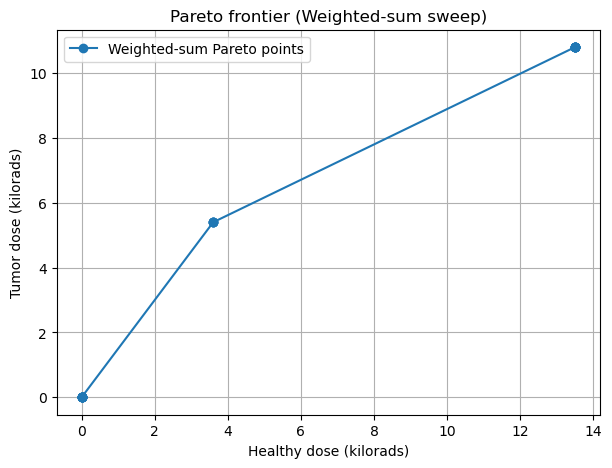

λ=0.00, Healthy=13.50, Tumor=10.80, x1=0.00, x2=27.00
λ=0.05, Healthy=13.50, Tumor=10.80, x1=0.00, x2=27.00
λ=0.10, Healthy=13.50, Tumor=10.80, x1=0.00, x2=27.00
λ=0.15, Healthy=13.50, Tumor=10.80, x1=0.00, x2=27.00
λ=0.20, Healthy=13.50, Tumor=10.80, x1=0.00, x2=27.00
λ=0.25, Healthy=13.50, Tumor=10.80, x1=0.00, x2=27.00
λ=0.30, Healthy=13.50, Tumor=10.80, x1=0.00, x2=27.00
λ=0.35, Healthy=13.50, Tumor=10.80, x1=0.00, x2=27.00
λ=0.40, Healthy=3.60, Tumor=5.40, x1=9.00, x2=0.00
λ=0.45, Healthy=3.60, Tumor=5.40, x1=9.00, x2=0.00
λ=0.50, Healthy=3.60, Tumor=5.40, x1=9.00, x2=0.00
λ=0.55, Healthy=3.60, Tumor=5.40, x1=9.00, x2=0.00
λ=0.60, Healthy=0.00, Tumor=0.00, x1=0.00, x2=0.00
λ=0.65, Healthy=0.00, Tumor=0.00, x1=0.00, x2=0.00
λ=0.70, Healthy=0.00, Tumor=0.00, x1=0.00, x2=0.00
λ=0.75, Healthy=0.00, Tumor=0.00, x1=0.00, x2=0.00
λ=0.80, Healthy=0.00, Tumor=0.00, x1=0.00, x2=0.00
λ=0.85, Healthy=0.00, Tumor=0.00, x1=0.00, x2=0.00
λ=0.90, Healthy=0.00, Tumor=0.00, x1=0.00, x2=0.00
λ=0.95,

In [ ]:
import gurobipy as gp
from gurobipy import GRB
import numpy as np
import matplotlib.pyplot as plt

# Sweep over lambda weights
lambdas = np.linspace(0, 1, 21)
results = []

for lam in lambdas:
    m = gp.Model("weighted_sum")
    m.setParam("OutputFlag", 0)
    
    # Decision variables
    x1 = m.addVar(lb=0.0, name="x1")
    x2 = m.addVar(lb=0.0, name="x2")
    
    # Objectives
    Healthy = 0.4*x1 + 0.5*x2
    Tumor   = 0.6*x1 + 0.4*x2
    
    # Weighted sum: minimize lam*Healthy - (1-lam)*Tumor
    m.setObjective(lam*Healthy - (1-lam)*Tumor, GRB.MINIMIZE)
    
    # Constraint: critical <= 2.7
    m.addConstr(0.3*x1 + 0.1*x2 <= 2.7)
    
    m.optimize()
    
    if m.Status == GRB.OPTIMAL:
        results.append({
            "lambda": lam,
            "Healthy": Healthy.getValue(),
            "Tumor": Tumor.getValue(),
            "x1": x1.X,
            "x2": x2.X
        })

# Plot Pareto points
Hs = [r["Healthy"] for r in results]
Ts = [r["Tumor"] for r in results]

plt.figure(figsize=(7,5))
plt.plot(Hs, Ts, 'o-', label="Weighted-sum Pareto points")
plt.xlabel("Healthy dose (kilorads)")
plt.ylabel("Tumor dose (kilorads)")
plt.title("Pareto frontier (Weighted-sum sweep)")
plt.grid(True)
plt.legend()
plt.show()

# Print a few points
for r in results:
    print(f"λ={r['lambda']:.2f}, Healthy={r['Healthy']:.2f}, Tumor={r['Tumor']:.2f}, x1={r['x1']:.2f}, x2={r['x2']:.2f}")
